# Assignment 09: Monitoring a Hospital-at-Home Program

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow

print("pandas:", pd.__version__)
print("pyarrow:", pyarrow.__version__)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

DAILY_FEED_PATH = OUTPUT_DIR / "daily_feed.csv"
COVERAGE_PATH = OUTPUT_DIR / "episode_coverage.csv"
ALERT_RULES_PATH = OUTPUT_DIR / "alert_rules.csv"
TURNAROUND_PATH = OUTPUT_DIR / "lab_turnaround.csv"
FEATURES_PATH = OUTPUT_DIR / "score_features.csv"
FIRST_HOUR_PATH = OUTPUT_DIR / "first_hour_features.csv"
HOLDOUT_PATH = OUTPUT_DIR / "holdout_summary.csv"

ALERT_BPM = 120  # Task 2.2: page a nurse at this heart rate
SCORE_AFTER = pd.Timedelta(hours=24)  # Task 3.2: the score runs this long after the admission hour
HOLDOUT_FROM = pd.Timestamp("2026-03-01", tz="UTC")  # Task 3.3: the holdout starts here
FLAG_BPM = 100  # Task 3.3: flag a mean_prev_6h at least this high

pandas: 3.0.5
pyarrow: 25.0.0


## Load the data

This cell downloads the three Parquet files from the course repository when `data/` lacks them (`urlretrieve(url, path)` saves the file at a web address to `path`), then reads them. Run it as it is.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/christopherseaman/datasci_217/main/09/assignment/data"
DATA_FILES = ["episodes.parquet", "vitals.parquet", "labs.parquet"]

DATA_DIR.mkdir(exist_ok=True)
for name in DATA_FILES:
    if not (DATA_DIR / name).exists():
        print("downloading", name)
        urlretrieve(f"{DATA_URL}/{name}", DATA_DIR / name)

episodes = pd.read_parquet(DATA_DIR / "episodes.parquet")
vitals_raw = pd.read_parquet(DATA_DIR / "vitals.parquet")
labs_raw = pd.read_parquet(DATA_DIR / "labs.parquet")
print("episodes:", episodes.shape)
print("vitals:", vitals_raw.shape)
print("labs:", labs_raw.shape)
episodes.head()

episodes: (1400, 9)
vitals: (577935, 3)
labs: (7356, 5)


,episode_id,patient_id,age,sex,deprivation_decile,diagnosis,admitted_at,ended_at,outcome
0,H00001,P00616,66,F,4,Pneumonia,2026-01-05 14:15:00+00:00,2026-01-08 15:42:00+00:00,discharged home
1,H00002,P01140,72,M,6,Cellulitis,2026-01-05 14:52:00+00:00,2026-01-10 13:32:00+00:00,discharged home
2,H00003,P00566,63,F,6,Urinary infection,2026-01-05 16:04:00+00:00,2026-01-09 05:56:00+00:00,discharged home
3,H00004,P00303,81,M,8,COPD,2026-01-05 16:45:00+00:00,2026-01-07 14:32:00+00:00,discharged home
4,H00005,P00261,72,M,4,Pneumonia,2026-01-05 17:27:00+00:00,2026-01-08 19:06:00+00:00,discharged home


## Task 1: Audit the feed by New York day

### 1.1 Parse and sort the readings

This step saves nothing.

In [3]:
vitals = vitals_raw.copy()
# TODO (README 1.1 step 1): overwrite vitals["recorded_at"] with aware UTC datetimes
vitals["recorded_at"] = pd.to_datetime(vitals["recorded_at"], utc=True)
# TODO (README 1.1 step 2): sort by episode, then time, and reset the index
vitals = vitals.sort_values(["episode_id", "recorded_at"]).reset_index(drop=True)
print("recorded_at dtype:", vitals["recorded_at"].dtype)
print("first reading:", vitals["recorded_at"].min())
print("no heart rate:", vitals["heart_rate"].isna().sum())
vitals.head()

recorded_at dtype: datetime64[us, UTC]
first reading: 2026-01-05 16:11:00+00:00
no heart rate: 5780


,episode_id,recorded_at,heart_rate
0,H00001,2026-01-05 16:11:00+00:00,80.0
1,H00001,2026-01-05 16:21:00+00:00,80.0
2,H00001,2026-01-05 16:31:00+00:00,81.0
3,H00001,2026-01-05 16:41:00+00:00,78.0
4,H00001,2026-01-05 16:51:00+00:00,76.0


### 1.2 Count each day's readings

> **Checkpoint: `output/daily_feed.csv`**
> The header line `date,readings,episodes`, then 87 rows. The first reads `2026-01-05 00:00:00-05:00,828,17`, and February 17 reads `2026-02-17 00:00:00-05:00,5836,79`.

In [4]:
local = vitals.copy()  # TODO (README 1.2 step 1): a copy of vitals with recorded_at on the New York clock
local["recorded_at"] = local["recorded_at"].dt.tz_convert("America/New_York")
daily = local.set_index("recorded_at").resample("D").agg(
    readings=("heart_rate", "size"),
    episodes=("episode_id", "nunique"),
)
# TODO (README 1.2 step 2): readings and episodes per New York day
print("days:", len(daily))

week = daily.loc["2026-02-14":"2026-02-20"].copy()  # TODO (README 1.2 step 3): February 14 to 20 from daily
week["per_episode"] = (week["readings"] / week["episodes"]).round(1)
display(week)

daily_feed = daily.reset_index().rename(columns={"recorded_at": "date"})  # TODO (README 1.2 step 4): the dates in a column named date
# TODO (README 1.2 step 4): save daily_feed to DAILY_FEED_PATH
daily_feed.to_csv(DAILY_FEED_PATH, index=False)

daily_feed.head()

days: 87


,readings,episodes,per_episode
recorded_at,,,
2026-02-14 00:00:00-05:00,7840,82,95.6
2026-02-15 00:00:00-05:00,5917,63,93.9
2026-02-16 00:00:00-05:00,6574,73,90.1
2026-02-17 00:00:00-05:00,5836,79,73.9
2026-02-18 00:00:00-05:00,7604,79,96.3
2026-02-19 00:00:00-05:00,8405,82,102.5
2026-02-20 00:00:00-05:00,7980,83,96.1


,date,readings,episodes
0,2026-01-05 00:00:00-05:00,828,17
1,2026-01-06 00:00:00-05:00,2855,35
2,2026-01-07 00:00:00-05:00,5068,50
3,2026-01-08 00:00:00-05:00,6120,64
4,2026-01-09 00:00:00-05:00,7341,79


## Task 2: Measure gaps and compare alert rules

### 2.1 Find each episode's monitoring gaps

> **Checkpoint: `output/episode_coverage.csv`**
> The header line `episode_id,grid_hours,gap_hours,gap_runs,longest_gap_h`, then 1,400 rows. `H00002` reads `H00002,117,7,3.0,3.0`: three gaps, the longest 3 hours. `H00004` has no gap: `H00004,46,0,0.0,0.0`.

In [5]:
# TODO (README 2.1 step 1): readings per episode and hour, the count named readings
# TODO (README 2.1 step 2): add source_observed and gap_hour
# TODO (README 2.1 step 3): add run_id, then build runs and run_summary
hourly_counts = (
    vitals.assign(source_row=1)
    .set_index("recorded_at")
    .groupby("episode_id")["source_row"]
    .resample("h")
    .count()
    .reset_index(name="readings")
)
hourly_counts["source_observed"] = hourly_counts["readings"] > 0
hourly_counts["gap_hour"] = ~hourly_counts["source_observed"]
hourly_counts["run_id"] = hourly_counts.groupby("episode_id")["source_observed"].cumsum()
runs = (
    hourly_counts[hourly_counts["gap_hour"]]
    .groupby(["episode_id", "run_id"])
    .size()
    .rename("gap_len")
    .reset_index()
)
run_summary = runs.groupby("episode_id").agg(
    gap_runs=("gap_len", "count"),
    longest_gap_h=("gap_len", "max"),
).reset_index()
print("hourly rows:", len(hourly_counts), " gap runs:", len(runs))

# TODO (README 2.1 step 4): grid_hours and gap_hours per episode, with run_summary merged on
coverage = hourly_counts.groupby("episode_id").agg(
    grid_hours=("gap_hour", "size"),
    gap_hours=("gap_hour", "sum"),
).reset_index()
coverage = coverage.merge(run_summary, on="episode_id", how="left", validate="one_to_one")
coverage[["gap_runs", "longest_gap_h"]] = coverage[["gap_runs", "longest_gap_h"]].fillna(0)
print("episodes:", len(coverage), " no gap:", (coverage["gap_runs"] == 0).sum())

# TODO (README 2.1 step 5): save coverage to COVERAGE_PATH
coverage.to_csv(COVERAGE_PATH, index=False)

by_area = coverage.merge(episodes[["episode_id", "deprivation_decile"]], on="episode_id", validate="one_to_one")
by_area["gap_share"] = by_area["gap_hours"] / by_area["grid_hours"]
display(by_area.groupby("deprivation_decile")["gap_share"].mean().round(3))
coverage.head()

hourly rows: 108293  gap runs: 3102
episodes: 1400  no gap: 201


deprivation_decile
1     0.045
2     0.044
3     0.051
4     0.051
5     0.054
6     0.056
7     0.071
8     0.068
9     0.066
10    0.072
Name: gap_share, dtype: float64

,episode_id,grid_hours,gap_hours,gap_runs,longest_gap_h
0,H00001,72,1,1.0,1.0
1,H00002,117,7,3.0,3.0
2,H00003,86,6,3.0,3.0
3,H00004,46,0,0.0,0.0
4,H00005,72,0,0.0,0.0


### 2.2 Compare three heart-rate alert rules

> **Checkpoint: `output/alert_rules.csv`**
> The header line `rule,episodes_flagged,escalations_flagged`, then 3 rows, one per rule. `any_reading,1211,138` is the first. The hourly median flags about one episode in 20 and the rolling rule about half as many. Compare how many of each rule's flags are escalations, and how many of the 179 escalations each rule misses: a fever or a fast atrial fibrillation raises the heart rate and settles at home, and some patients get worse without a fast heart rate.

In [6]:
# TODO (README 2.2 step 1): each episode's hourly median heart rate
hourly = (
    vitals.set_index("recorded_at")
    .groupby("episode_id")["heart_rate"]
    .resample("h")
    .median()
    .reset_index()
)
# TODO (README 2.2 step 2): add rolling_3h
hourly["rolling_3h"] = hourly.groupby("episode_id")["heart_rate"].transform(
    lambda s: s.rolling(3).mean()
)
print("hourly:", hourly.shape)

peaks = pd.DataFrame({
    "any_reading": vitals.groupby("episode_id")["heart_rate"].max(),
    "hourly_median": hourly.groupby("episode_id")["heart_rate"].max(),
    "rolling_3h": hourly.groupby("episode_id")["rolling_3h"].max(),
})
# TODO (README 2.2 step 3): each episode's highest any_reading, hourly_median, and rolling_3h
flags = peaks >= ALERT_BPM
escalated = flags.index.isin(episodes.loc[episodes["outcome"] == "escalated", "episode_id"])
print("escalated:", escalated.sum())

alert_rules = (
    pd.DataFrame({
        "episodes_flagged": flags.sum(),
        "escalations_flagged": flags[escalated].sum(),
    })
    .reset_index()
    .rename(columns={"index": "rule"})
)
alert_rules.to_csv(ALERT_RULES_PATH, index=False)
# TODO (README 2.2 step 4): one row per rule
# TODO (README 2.2 step 5): save alert_rules to ALERT_RULES_PATH

alert_rules

hourly: (108293, 4)
escalated: 179


,rule,episodes_flagged,escalations_flagged
0,any_reading,1211,138
1,hourly_median,71,35
2,rolling_3h,36,18


### 2.3 Plot one escalated episode

This step saves nothing.

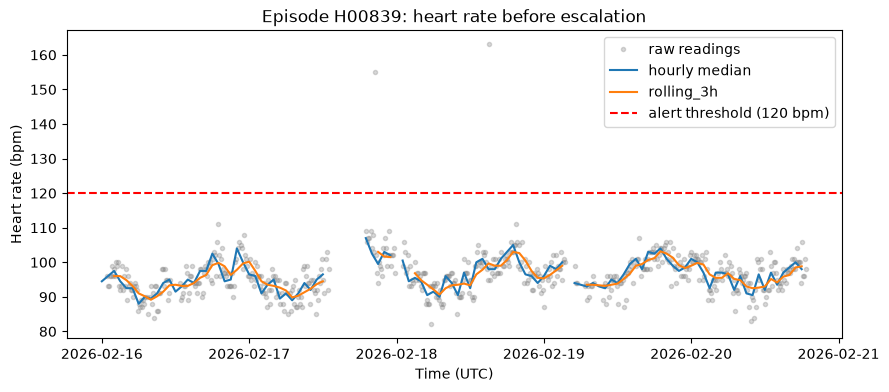

In [7]:
ONE = "H00839"
fig, ax = plt.subplots(figsize=(10, 4))
# TODO (README 2.3): the raw readings, the hourly median and rolling_3h lines, a dashed line at ALERT_BPM,
#   a title, axis labels, and a legend
raw_one = vitals[vitals["episode_id"] == ONE]
hourly_one = hourly[hourly["episode_id"] == ONE]

ax.plot(raw_one["recorded_at"], raw_one["heart_rate"], ".", color="gray", alpha=0.3, label="raw readings")
ax.plot(hourly_one["recorded_at"], hourly_one["heart_rate"], label="hourly median")
ax.plot(hourly_one["recorded_at"], hourly_one["rolling_3h"], label="rolling_3h")
ax.axhline(ALERT_BPM, linestyle="--", color="red", label=f"alert threshold ({ALERT_BPM} bpm)")
ax.set(title=f"Episode {ONE}: heart rate before escalation", xlabel="Time (UTC)", ylabel="Heart rate (bpm)")
ax.legend()
plt.show()

## Task 3: Score each episode at 24 hours

### 3.1 Put the lab times on UTC and measure turnaround

> **Checkpoint: `output/lab_turnaround.csv`**
> The header line `test,orders,timed_results,median_turnaround_h`, then 5 rows, one per test. `Lactate` has 1,253 orders, 1,250 of them timed, and a median turnaround of about 3.5 hours: a sample drawn at home rides a courier to the lab.

In [8]:
labs = labs_raw.copy()
for column in ["collected_at", "resulted_at"]:
    # TODO (README 3.1 step 1): parse, localize to New York with NaT for clock-change times, convert to UTC
    labs[column] = (
            pd.to_datetime(labs[column], format="%Y-%m-%d %H:%M")
            .dt.tz_localize("America/New_York", ambiguous="NaT", nonexistent="NaT")
            .dt.tz_convert("UTC")
        )
print("set aside:", labs[["collected_at", "resulted_at"]].isna().sum().to_dict())
display(labs_raw[labs["resulted_at"].isna()])

# TODO (README 3.1 step 2): add turnaround_h
# TODO (README 3.1 step 3): one row per test
# TODO (README 3.1 step 4): save lab_turnaround to TURNAROUND_PATH
labs["turnaround_h"] = (labs["resulted_at"] - labs["collected_at"]).dt.total_seconds() / 3600
lab_turnaround = labs.groupby("test", as_index=False).agg(
    orders=("test", "size"),
    timed_results=("resulted_at", "count"),
    median_turnaround_h=("turnaround_h", "median"),
)
lab_turnaround.to_csv(TURNAROUND_PATH, index=False)
lab_turnaround

set aside: {'collected_at': 0, 'resulted_at': 10}


,episode_id,test,collected_at,resulted_at,value
5945,H01123,Lactate,2026-03-07 17:14,2026-03-08 02:22,2.03
5948,H01124,BMP,2026-03-07 20:18,2026-03-08 02:00,0.96
5949,H01124,BNP,2026-03-07 20:18,2026-03-08 02:26,1846.17
5951,H01124,Lactate,2026-03-07 20:18,2026-03-08 02:29,1.39
5958,H01125,CBC,2026-03-07 19:26,2026-03-08 02:29,8.28
5963,H01126,BMP,2026-03-07 18:58,2026-03-08 02:16,0.98
5965,H01126,CBC,2026-03-07 18:58,2026-03-08 02:07,11.10
5971,H01128,BMP,2026-03-07 22:13,2026-03-08 02:16,0.74
5972,H01128,CBC,2026-03-07 22:13,2026-03-08 02:07,9.93
5973,H01128,Lactate,2026-03-07 22:13,2026-03-08 02:00,1.51


,test,orders,timed_results,median_turnaround_h
0,BMP,4190,4187,3.900000
1,BNP,277,276,5.225000
2,CBC,1498,1495,3.900000
3,INR,138,138,3.591667
4,Lactate,1253,1250,3.466667


### 3.2 Build past-only features at the prediction time

> **Checkpoint: `output/score_features.csv`**
> The header line `episode_id,prev_hour_hr,mean_prev_6h,last_lactate`, then 1,359 rows. `H00001`, scored at `2026-01-06 14:00:00+00:00`, reads `H00001,86.5,78.75,` with no lactate yet; `H00007` has a `last_lactate` of `1.71`. `prev_hour_hr` is blank for 82 episodes whose previous hour was a gap.

> **Checkpoint: `output/first_hour_features.csv`**
> The header line `episode_id,prev_hour_hr,mean_prev_6h`, then 1,400 rows, each an episode ID followed by two blanks, such as `H00002,,`. A number there is another patient's heart rate.

In [9]:
# TODO (README 3.2 step 1): episode_id, admitted_at, outcome, and prediction_time
scored = episodes[["episode_id", "admitted_at", "outcome"]].copy()
scored["prediction_time"] = scored["admitted_at"].dt.floor("h") + SCORE_AFTER

features = hourly[["episode_id", "recorded_at", "heart_rate"]].copy()
# TODO (README 3.2 step 2): add prev_hour_hr and mean_prev_6h within each episode
by_episode = features.groupby("episode_id")["heart_rate"]
features["prev_hour_hr"] = by_episode.shift(1)
features["mean_prev_6h"] = by_episode.transform(lambda s: s.shift(1).rolling(6, min_periods=1).mean())

first_hours = features.groupby("episode_id").head(1)  # TODO (README 3.2 step 3): each episode's first row of features
print("first hours:", len(first_hours), " with prev_hour_hr:", first_hours["prev_hour_hr"].notna().sum(),
      " with mean_prev_6h:", first_hours["mean_prev_6h"].notna().sum())
# TODO (README 3.2 step 3): save episode_id, prev_hour_hr, and mean_prev_6h to FIRST_HOUR_PATH
first_hours[["episode_id", "prev_hour_hr", "mean_prev_6h"]].to_csv(FIRST_HOUR_PATH, index=False)
display(first_hours.head())

# TODO (README 3.2 step 4): merge scored, then keep the rows at the prediction time
score_features = features.merge(scored, on="episode_id", validate="many_to_one")
score_features = score_features[score_features["recorded_at"] == score_features["prediction_time"]]
print("scored:", len(score_features))

lactate = labs[labs["test"] == "Lactate"].merge(
    scored[["episode_id", "prediction_time"]], on="episode_id", validate="many_to_one"
)  # TODO (README 3.2 step 5): the Lactate rows of labs, with prediction_time merged on
known = lactate[lactate["resulted_at"] <= lactate["prediction_time"]]  # TODO (README 3.2 step 5): the lactates resulted by the prediction time
print("lactates:", len(lactate), " known:", len(known), "from", known["episode_id"].nunique(), "episodes")
last_lactate = (
    known.sort_values("resulted_at", kind="stable")
    .groupby("episode_id")
    .tail(1)[["episode_id", "value"]]
    .rename(columns={"value": "last_lactate"})
)  # TODO (README 3.2 step 5): each episode's latest known value, named last_lactate

# TODO (README 3.2 step 6): left-merge last_lactate onto score_features
# TODO (README 3.2 step 7): save episode_id and the three features to FEATURES_PATH
score_features = score_features.merge(last_lactate, on="episode_id", how="left", validate="one_to_one")
score_features[["episode_id", "prev_hour_hr", "mean_prev_6h", "last_lactate"]].to_csv(FEATURES_PATH, index=False)

score_features.head()

first hours: 1400  with prev_hour_hr: 0  with mean_prev_6h: 0


,episode_id,recorded_at,heart_rate,prev_hour_hr,mean_prev_6h
0,H00001,2026-01-05 16:00:00+00:00,80.0,NaN,NaN
72,H00002,2026-01-05 17:00:00+00:00,73.0,NaN,NaN
189,H00003,2026-01-05 16:00:00+00:00,68.0,NaN,NaN
275,H00004,2026-01-05 17:00:00+00:00,82.0,NaN,NaN
321,H00005,2026-01-05 19:00:00+00:00,74.0,NaN,NaN


scored: 1359
lactates: 1253  known: 708 from 618 episodes


,episode_id,recorded_at,heart_rate,prev_hour_hr,mean_prev_6h,admitted_at,outcome,prediction_time,last_lactate
0,H00001,2026-01-06 14:00:00+00:00,77.5,86.5,78.750000,2026-01-05 14:15:00+00:00,discharged home,2026-01-06 14:00:00+00:00,NaN
1,H00002,2026-01-06 14:00:00+00:00,67.0,68.0,63.000000,2026-01-05 14:52:00+00:00,discharged home,2026-01-06 14:00:00+00:00,NaN
2,H00003,2026-01-06 16:00:00+00:00,68.5,69.5,64.000000,2026-01-05 16:04:00+00:00,discharged home,2026-01-06 16:00:00+00:00,NaN
3,H00004,2026-01-06 16:00:00+00:00,86.0,88.0,78.416667,2026-01-05 16:45:00+00:00,discharged home,2026-01-06 16:00:00+00:00,NaN
4,H00005,2026-01-06 17:00:00+00:00,75.0,72.5,71.500000,2026-01-05 17:27:00+00:00,discharged home,2026-01-06 17:00:00+00:00,NaN


### 3.3 Summarize a chronological holdout

> **Checkpoint: `output/holdout_summary.csv`**
> The header line `block,episodes,escalations,flagged,flagged_escalations`, then 2 rows. `earlier` holds 994 episodes and 107 escalations; `later_holdout` holds 365.

In [10]:
blocks = score_features.copy()
# TODO (README 3.3 step 1): add block
# TODO (README 3.3 step 2): add escalated, flagged, and flagged_escalation
# TODO (README 3.3 step 3): one row per block
# TODO (README 3.3 step 4): save holdout to HOLDOUT_PATH
blocks["block"] = np.where(blocks["prediction_time"] < HOLDOUT_FROM, "earlier", "later_holdout")
blocks["escalated"] = blocks["outcome"] == "escalated"
blocks["flagged"] = blocks["mean_prev_6h"] >= FLAG_BPM
blocks["flagged_escalation"] = blocks["escalated"] & blocks["flagged"]
holdout = blocks.groupby("block", as_index=False).agg(
    episodes=("episode_id", "size"),
    escalations=("escalated", "sum"),
    flagged=("flagged", "sum"),
    flagged_escalations=("flagged_escalation", "sum"),
)
holdout.to_csv(HOLDOUT_PATH, index=False)
rates = holdout.set_index("block")
display(pd.DataFrame({
    "escalation_rate": rates["escalations"] / rates["episodes"],
    "flagged_that_escalated": rates["flagged_escalations"] / rates["flagged"],
}).round(3))
holdout

,escalation_rate,flagged_that_escalated
block,,
earlier,0.108,0.436
later_holdout,0.085,0.333


,block,episodes,escalations,flagged,flagged_escalations
0,earlier,994,107,39,17
1,later_holdout,365,31,6,2


## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [11]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  3/3  daily feed: columns
[PASS]  4/4  daily feed: one row per New York day
[PASS]  5/5  daily feed: readings values
[PASS]  4/4  daily feed: episodes values
[PASS]  3/3  episode coverage: columns
[PASS]  4/4  episode coverage: one row per episode
[PASS]  5/5  episode coverage: grid_hours and gap_hours values
[PASS]  5/5  episode coverage: gap_runs and longest_gap_h values
[PASS]  3/3  alert rules: columns
[PASS]  3/3  alert rules: one row per rule
[PASS]  5/5  alert rules: episodes_flagged values
[PASS]  5/5  alert rules: escalations_flagged values
[PASS]  3/3  lab turnaround: columns
[PASS]  2/2  lab turnaround: one row per test
[PASS]  4/4  lab turnaround: orders and timed_results values
[PASS]  4/4  lab turnaround: median_turnaround_h values
[PASS]  3/3  score features: columns
[PASS]  4/4  score features: one row per scored episode
[PASS]  4/4  score features: prev_hour_hr values
[PASS]  4/4  score features: mean_prev_6h val